# Phase-Aligned Metamers: Walkthrough
In a foveated image, the periphery is blurred to match the falling acuity of the eye. The blur also removes fine texture, which makes the periphery look smeared instead of just less sharp. This notebook replaces the missing detail with **phase-aligned noise**: synthesized noise whose local orientation, phase and contrast follow the image's own statistics. Where a pyramid level is blurred away, those statistics are extrapolated from the next coarser level, which is still present.

The notebook runs the pipeline step by step on `images/face.jpg`:

1. **Part 1: Setup** (once per display): screen geometry, image size and the noise generator. These stay constant as long as the display and the image resolution do.
2. **Part 2: Per Frame** (for every image or video frame): viewer position and gaze, image loading and foveation, then the four stages of the method: **Analysis** of local statistics, **Repair** (extrapolation into the periphery), noise **Synthesis** and **Composition**.
3. **Part 3: Experiments**: variations of the pipeline and a display of intermediate maps.

Every code cell only computes. The images and plots are shown by the cell right after it, which starts with `# render images` and has its code collapsed.

The cell below imports the package. Every class has its own module in `phase_aligned_metamers/`. `imagestats_utils` (`isu`) holds shared helpers for color conversion, pyramids, upsampling, plotting and saving.

In [1]:
import torch

import phase_aligned_metamers.imagestats_utils as isu
from phase_aligned_metamers.view_config import ViewConfig
from phase_aligned_metamers.image import Image
from phase_aligned_metamers.worm import Worm
from phase_aligned_metamers.noise_generator import NoiseGenerator

# Part 1: Setup (Per Display)
This part sets up what stays the same during a session: the display (its pixel pitch) and the noise generator. It also gives the image size, viewer position and gaze their initial values. Viewer position and gaze can change from frame to frame, and the image size can change too, e.g. when the image is rescaled; Part 2 shows how to update them.

## General Properties
- `SCREEN_WIDTH_CM`, `SCREEN_WIDTH_PX`: physical width and horizontal resolution of the display. Together they define the pixel pitch (cm per pixel), which converts pixel distances on the screen into visual angle.
- `MAX_PYR_DEPTH`: number of pyramid levels (L0 to L4) considered for the foveation. The eccentricity-to-level mapping from our calibration study reaches its coarsest level, L4, at 24° eccentricity, so five levels are enough.
- `DEVICE`: the device all tensors live on. A CUDA GPU is used if available; everything also runs on the CPU, just more slowly.

In [2]:
SCREEN_WIDTH_CM = 120  # physical display width [cm]
SCREEN_WIDTH_PX = 3840  # horizontal display resolution [px]
MAX_PYR_DEPTH = 5  # maximum depth of image pyramids
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # common device

## Screen Properties and Viewing Condition
`ViewConfig` describes the display and, as a starting point, where the viewer is and where they look:
- `screen_width_cm`, `screen_width_px`: the display's width in cm and px, i.e. its pixel pitch.
- `img_size`: size of the input image as `[1, C, H, W]` in px. The image is assumed to be centered on the screen.
- `viewing_distance`: the observer's distance to the screen in cm, with the viewer centered in front of the image.
- `gaze_pos_px`: gaze point as (row, col) in image pixels, measured from the top-left pixel (row downwards, col to the right), using pixel centers. Default: image center.
- `viewer_pos_cm`: optional 3D eye position (vertical, horizontal, distance) in cm relative to the image center, with vertical pointing down and horizontal pointing right. Overrides `viewing_distance`.

Only the pixel pitch is fixed; image size, viewer position and gaze are initial values that can be updated later (see Part 2).

From these, `ViewConfig` computes three maps with one value per pixel:
- `ecc_map`: **eccentricity**, the visual angle in degrees between the gaze direction and the direction to that pixel.
- `pyr_level_map`: the **pyramid level** that matches the visual acuity at that eccentricity. The mapping is piecewise linear: level 0 (full resolution) up to 4°, then levels 2, 3 and 4 at 8°, 16° and 24°. Non-integer values mean a blend between two neighboring levels.
- `kernel_map`: the **Gaussian blur sigma** (in px) that gives the same blur as that pyramid level, upsampled to full resolution.

In [3]:
view_config = ViewConfig(
    device=DEVICE,
    screen_width_cm=SCREEN_WIDTH_CM,
    screen_width_px=SCREEN_WIDTH_PX,
    img_size=[1, 1, 1024, 2048],  # [1, C, H, W]; access as view_config.img_size
    viewing_distance=100,         # [cm]
    # gaze_pos_px=(512, 1024),    # optional (row, col); default: image center
    # viewer_pos_cm=(0, 0, 100),  # optional (vertical, horizontal, distance) [cm]
    _debug=True,
)

ViewConfig:
  - Image size:              [1, 1, 1024, 2048]
  - Image size (H x W):      32.00 x 64.00 cm
  - Pixel pitch:             32.0 px/cm
  - Viewer position (cm):    vertical 0.0, horizontal 0.0, distance 100
  - Gaze position (px):      (512, 1024)
  - Eccentricity range:      0.00 - 19.69 deg
  - Pyramid level range:     0.00 - 3.46


## Enhancement Signal Generator
The enhancement signal is a sparse convolution noise: impulses on a regular grid, each replaced by a small steerable filter (a second derivative of a Gaussian and its Hilbert transform) that is rotated, phase-shifted and scaled by the local statistics at its position.

The impulses lie on a grid with a spacing of 8 px. `impulse_offsets` is a list of (row, col) offsets within one 8×8 cell at which impulse grids are placed. With all 64 offsets (as below), every pixel carries an impulse, i.e. the densest noise. Fewer offsets give a sparser noise and a faster synthesis; `None` also means all 64.

The filtered impulse grids do not depend on the image, so `NoiseGenerator` precomputes them once at initialization. `generate_noise` resets the generator itself, so it can be called repeatedly without further setup.

In [4]:
IMPULSE_OFFSETS = [(r, c) for r in range(8) for c in range(8)]  # all 64: densest noise
noise_gen = NoiseGenerator(size=view_config.img_size, impulse_offsets=IMPULSE_OFFSETS)

# Part 2: Image Processing (Per Frame)
Everything in this part is repeated for every image or video frame: the viewer position and gaze are set, the image is loaded and foveated, and the four stages of the method run on it. It reuses `view_config` and `noise_gen` from Part 1.

## Viewer Position, Gaze and Image Size
Call `view_config.update(gaze_pos_px=..., viewer_pos_cm=..., img_size=...)` to set the viewer, the gaze or a new image size for the current frame (arguments left out keep their value); this recomputes all three maps. Everything built from the maps has to follow:
- `img.update_foveation(view_config.kernel_map)` foveates the image for the new maps. After a size change, load the rescaled `Image` and create a new `NoiseGenerator` instead, since both are built for one resolution.
- The `Worm` is rebuilt. In principle, the input of the method is the foveated image, which changes with every new gaze, so its pyramids and statistics have to be computed again. This notebook (like the paper) takes a shortcut and analyzes the full-resolution original instead, then keeps each level's statistics only where that level still exists in the foveated image (see Analysis). The masks, the cutoff, the repair and the synthesis still depend on the gaze.

Here the gaze is moved to row 400, column 700. `gaze_pos_px` is (row, col) in image pixels, measured from the top-left pixel (row downwards, col to the right), using pixel centers.

In [5]:
view_config.update(gaze_pos_px=(400, 700))
# img.update_foveation(view_config.kernel_map)  # after a later update; rebuild the Worm

The three maps for the current viewing condition. Eccentricity grows with the distance from the gaze point; the pyramid level and the blur sigma follow it. Around the gaze point the image stays sharp (level 0) and only the periphery is blurred.


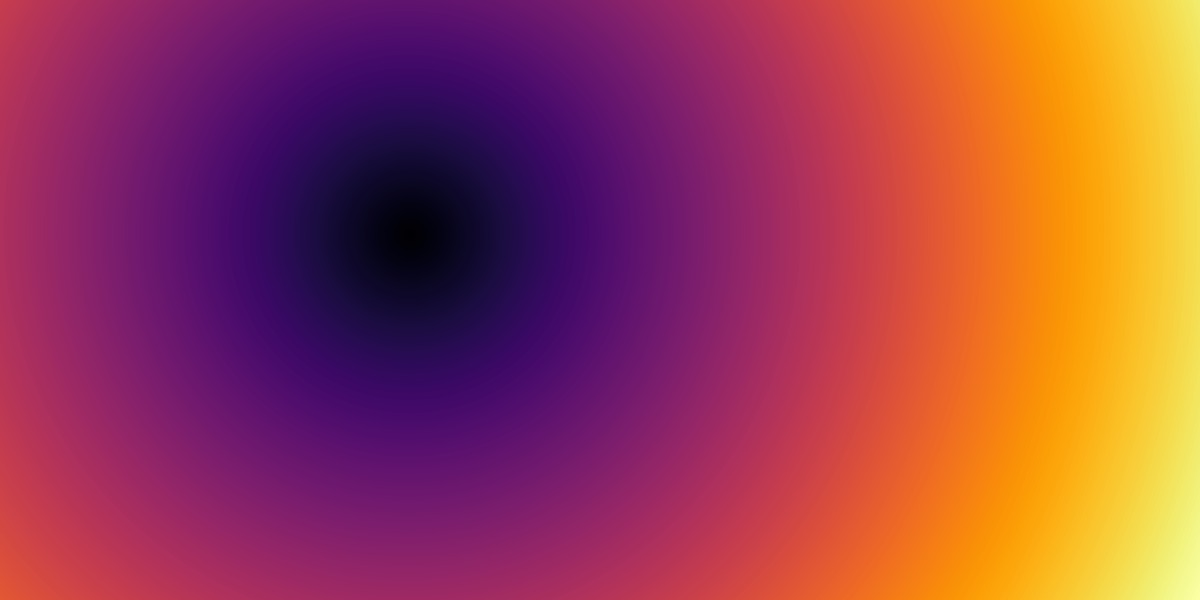
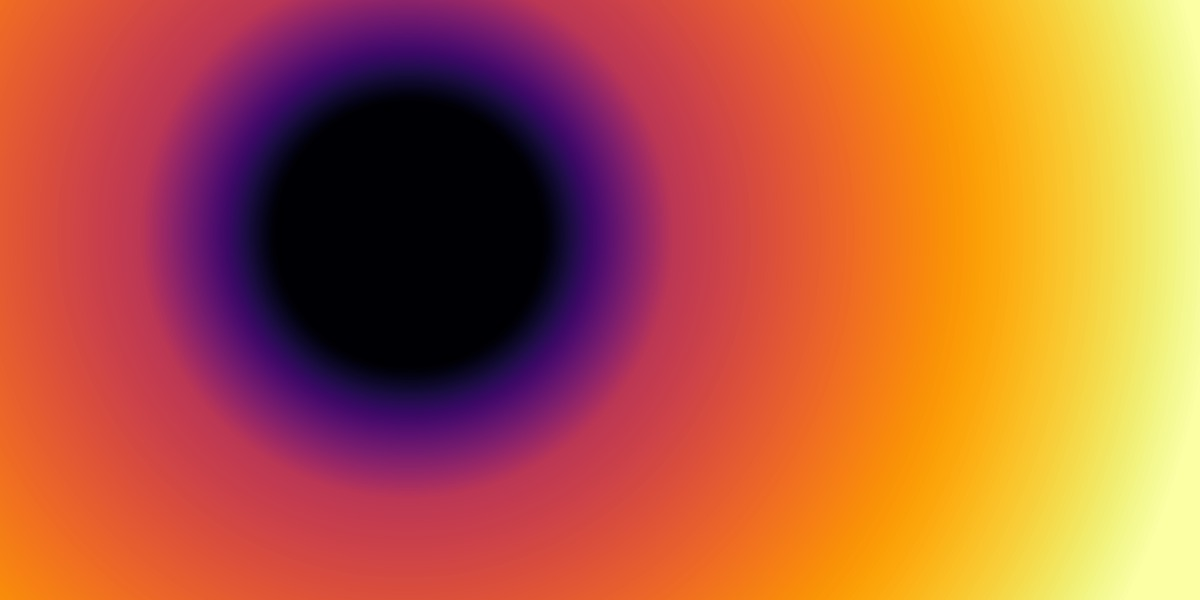
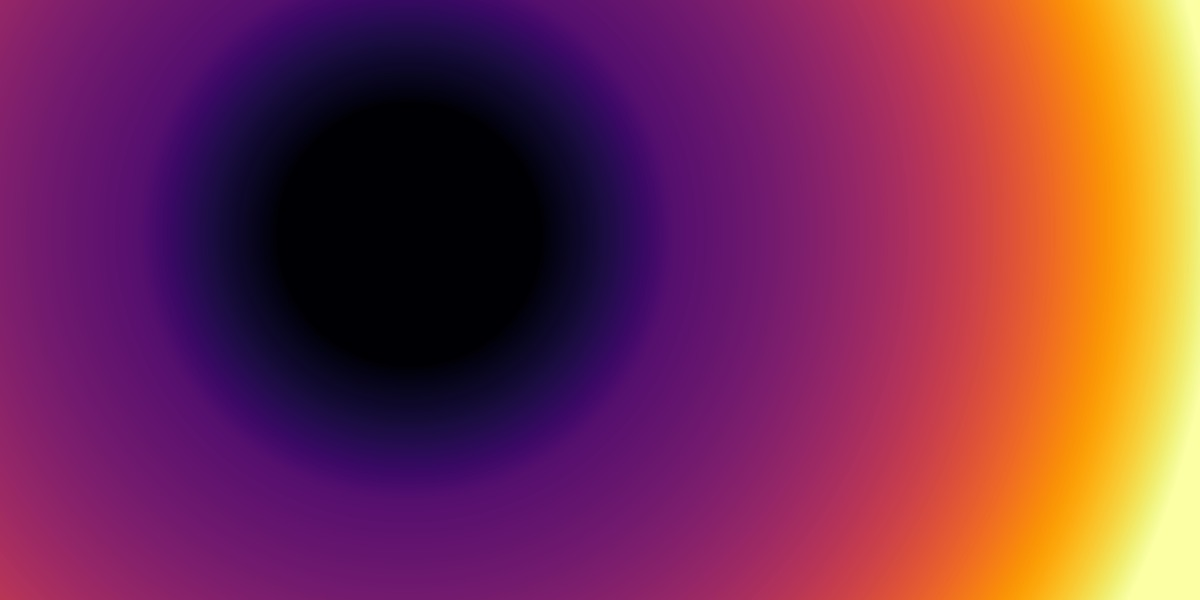

In [6]:
# render images
isu.show_multiple(
    [view_config.ecc_map.cpu(),
     view_config.pyr_level_map.cpu(),
     view_config.kernel_map.cpu()],
    title=['Eccentricity per Pixel (deg)',
           'Pyramid Level per Pixel',
           'Equivalent Blur Sigma per Pixel (px)'],
)

## Load Image and Prepare Foveated Versions
`Image` loads the image (8 or 16 bit, color or grayscale) and prepares:
- `img.rgb`: the image in RGB, values in [0, 1].
- `img.ycbcr`: the same image in YCbCr. The analysis and the noise only use the luma channel Y; the chroma channels Cb and Cr are foveated but get no enhancement signal.
- `img.fov`: the foveated version of `img.ycbcr`, blurred per pixel with a Gaussian of sigma `view_config.kernel_map`. This is the reference foveation: accurate but expensive, since every pixel has its own kernel. This foveation just serves as a baseline and is not used in the real application.

In [7]:
img = Image(
    device=DEVICE,
    path='images/face.jpg',
    kernels=view_config.kernel_map,
    _debug=True,
)

Image loaded with shape torch.Size([1, 3, 1024, 2048])



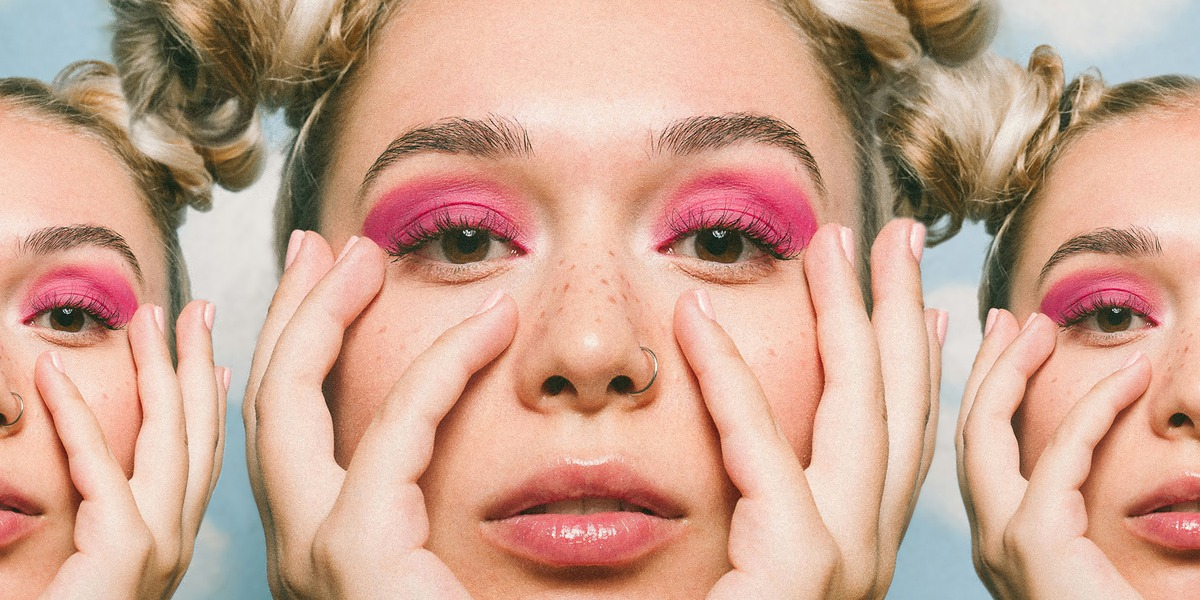
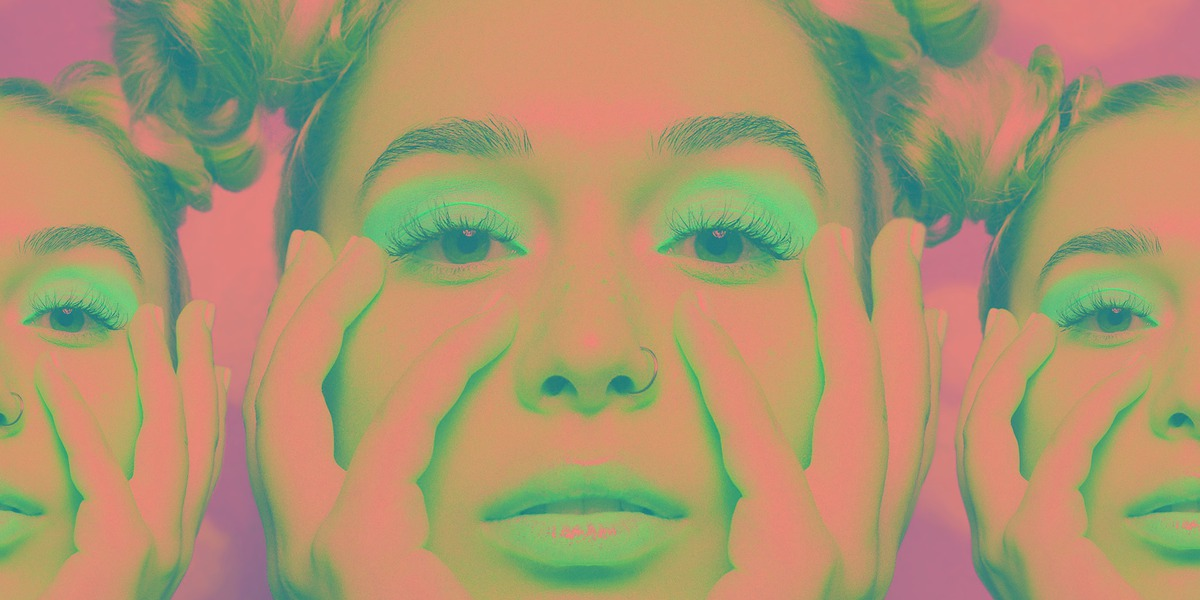


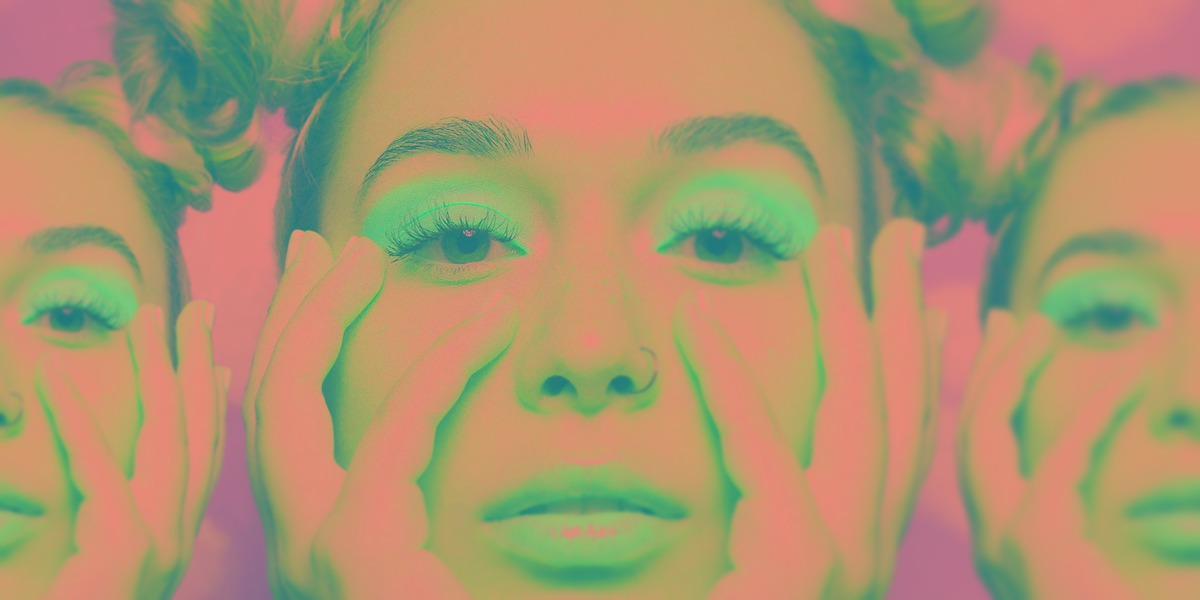
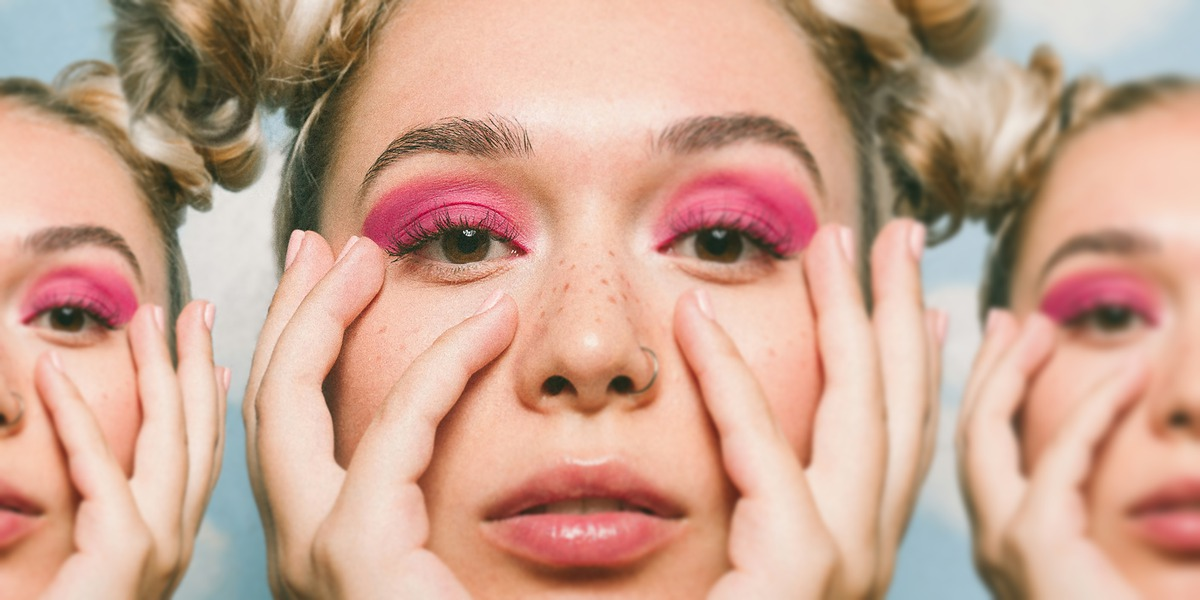

In [8]:
# render images
isu.show_multiple([img.rgb.cpu(), img.ycbcr.cpu()],
                  title=['Original Image (RGB)', 'Original Image (YCbCr)'])
isu.show_multiple([img.fov.cpu(), isu.ycrcb_2_rgb(img.fov.cpu())],
                  title=['Foveated Image (YCbCr)', 'Foveated Image (RGB)'])

## Set Up the Worm
The `Worm` holds everything that is computed per pyramid level. On creation it builds:
- the **Gaussian pyramid** of Y, Cb and Cr, and the **Laplacian pyramid** of Y (the band-pass detail of each level),
- the **masks** per level: 1 where the level is still resolved at the current viewing condition, 0 where it is blurred away and our signal has to replace it,
- the **rings**: the differences between consecutive masks, i.e. the region in which each level is the finest one still visible,
- the **cutoff**: the coarsest level that is needed. Levels below the cutoff (the finer ones) get noise; the cutoff level and coarser levels are resolved everywhere and serve as the source for the extrapolation.

The results are stored in these attributes:
- `maps.cutoff` (int): the cutoff level.
- `maps.depth` (int, cutoff + 1): the number of levels up to and including the cutoff.
- `maps.y` (list of dicts, one per level): the luma pyramid. Keys: `'img'` (Gaussian level), `'laplace'` (Laplacian band), later `'R'`, `'dir'`, `'phase'`, `'intensity'` and the repaired copies `'*_rep'`. It holds a few more levels than `depth`, which the analysis and the intensity fit need.
- `maps.cb`, `maps.cr` (same structure for the chroma channels; `None` for grayscale images).
- `maps.a` (list of dicts, one per level up to the cutoff): `'mask'`, `'mask_FR'`, `'ring'` and `'ring_small'`, each a tensor of shape [1, 1, H, W]. `'mask'` and `'ring_small'` have the size of their level; `'mask_FR'` and `'ring'` have the full resolution.
- `maps.meta` (list of dicts, one per level): the size of each level, `'size'`.

`compute_foveated_imgs()` builds a cheap, application-oriented foveation by upsampling each Gaussian level and blending the levels with the rings.

In [9]:
maps = Worm(
    device=DEVICE,
    img=img.ycbcr,
    pyr_level_map=view_config.pyr_level_map,
    MAX_DEPTH=MAX_PYR_DEPTH,
    fit_levels=None,  # levels above the cutoff for the intensity fit; None: all
    _debug=True,      # prints a summary of the pyramids
)
maps.compute_foveated_imgs()  # cheap foveation: blends the upsampled Gaussian levels

Worm initialized with:
  - Image size:              torch.Size([1024, 2048])
  - Cutoff layer:            4
  - Pyramid depth:           5
  - Levels for intensity fit: 3 (levels 4..6)
  - Y channel layers:        8
  - Cb channel layers:       8
  - Cr channel layers:       8


## Analysis
The analysis measures the local statistics of the luma channel Y at every pyramid level.

**Note:** in principle, the statistics would be measured on the foveated image. There, a pyramid level only exists inside its mask: outside, the foveation has blurred it away. For simplicity, the analysis here runs on the full-resolution original (as in the paper), which yields values for every level everywhere. All values outside a level's mask describe detail that does not exist in the foveated image, so they are discarded: the repair replaces them with values extrapolated from the coarser levels.
- `compute_R`: filters the level with seven steerable filters (three for the second derivative of a Gaussian, G, and four for its Hilbert transform, H).
- `compute_theta`: the **dominant orientation** per pixel (`'dir'`, in [-π/2, π/2]).
- `compute_steered_G_H`: rotates G and H to that orientation, which gives a complex response G + iH per pixel.
- `compute_phase`: the **local phase** (`'phase'`), the angle of G + iH. It says whether the local structure is a line, an edge or something in between.
- `compute_intensity_modulators`: the **noise amplitude** per level. A line is fitted through the standard deviation of the Laplacian bands from the cutoff on and extrapolated to the finer levels. The local `'intensity'` is the filter magnitude |G + iH| times this amplitude.
- `add_repaired_layer_proxies`: copies the statistics into `'intensity_rep'`, `'dir_rep'` and `'phase_rep'`. The repair writes into these copies, so the measured originals stay available for comparison.

The render cell shows the fit and the measured statistics of L0 (phase, orientation and intensity) only where L0 exists, i.e. where its mask is > 0. The discarded regions are gray.

In [10]:
maps.y = maps.compute_R(maps.y)                     # 7 steerable filter responses
maps.y = maps.compute_theta(maps.y)                 # dominant orientation
maps.y = maps.compute_steered_G_H(maps.y)           # steered response G + iH
maps.y = maps.compute_phase(maps.y)                 # local phase: angle of G + iH
maps.y = maps.compute_intensity_modulators(maps.y)  # noise amplitude per level
maps.y = maps.add_repaired_layer_proxies(maps.y)    # '_rep' copies for the repair


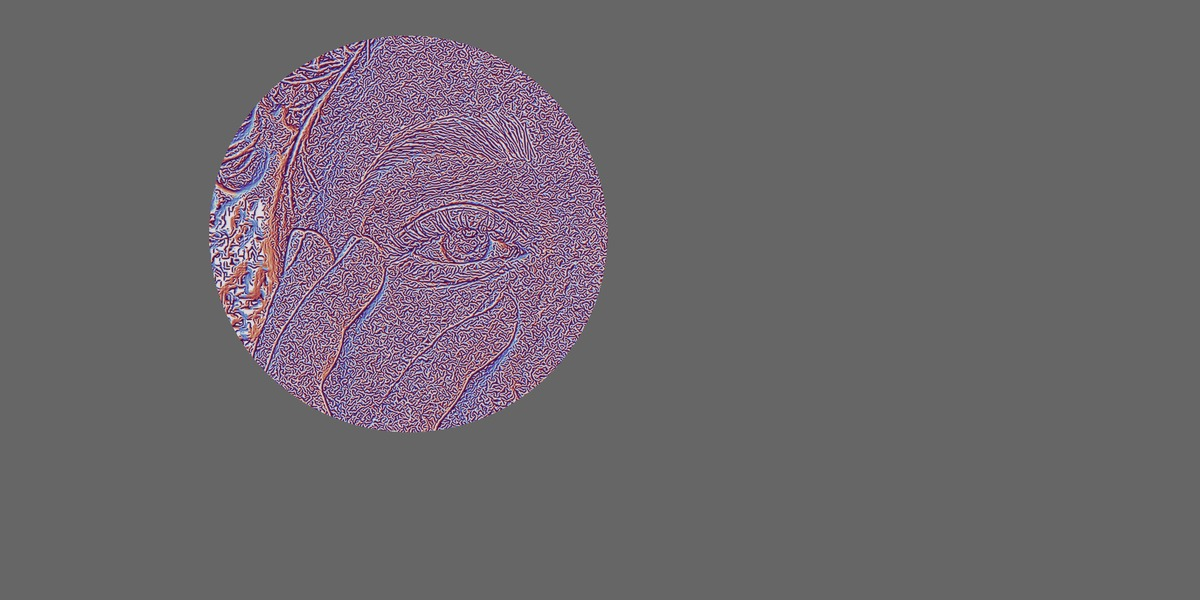


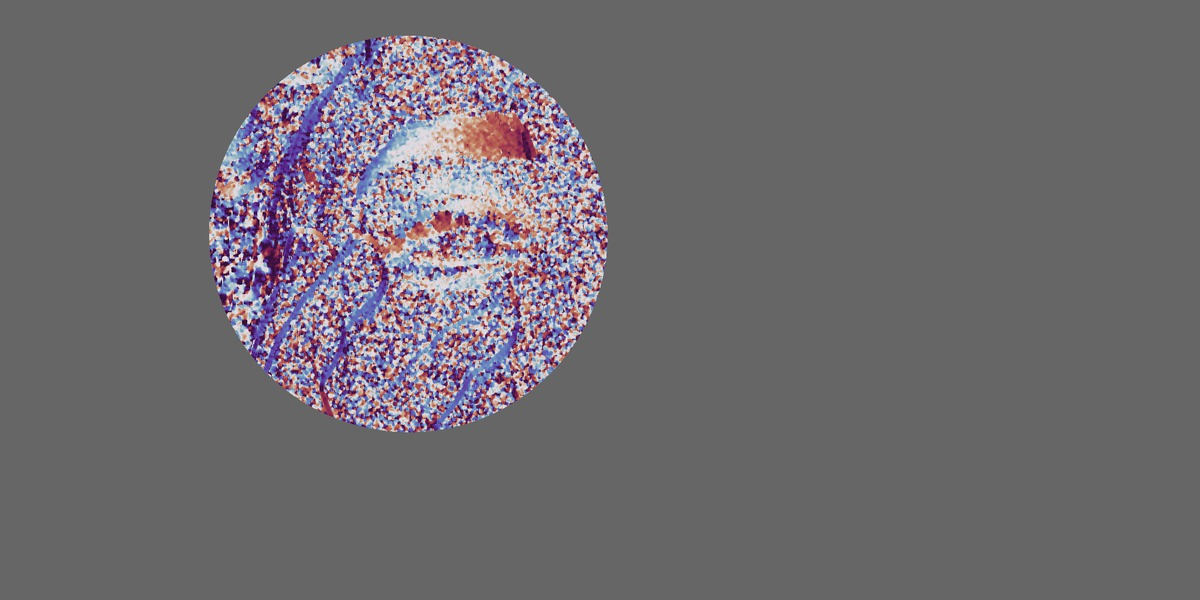


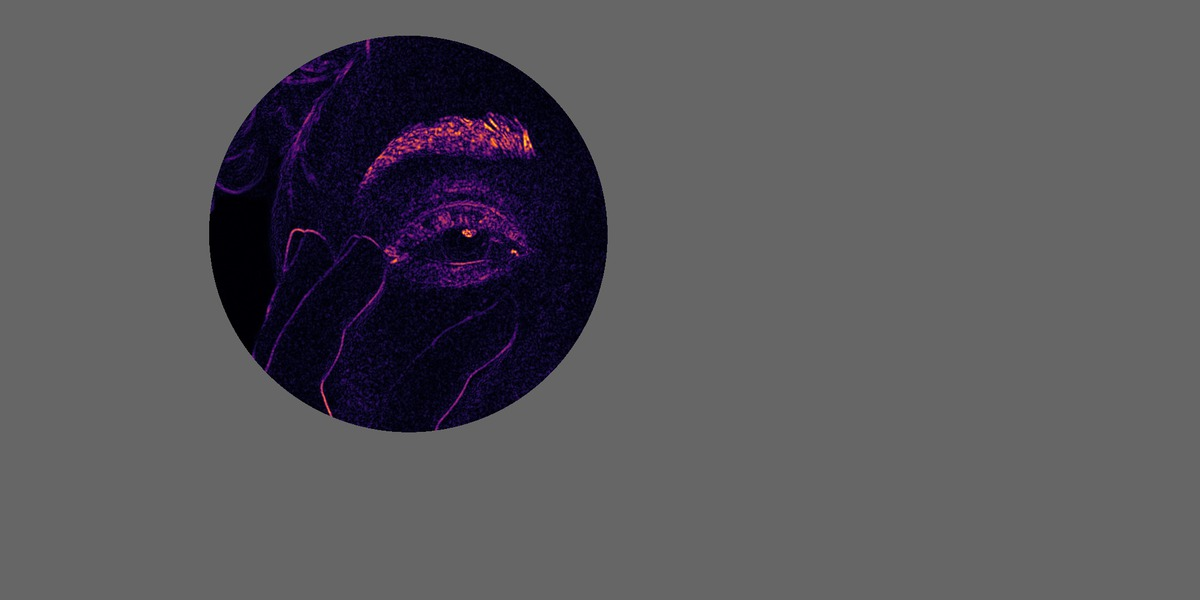

In [11]:
# render images
fit = maps.fit
maps.plot_intensity_fit(maps.y, fit['levels'], fit['std'], fit['m'], fit['b'])

# measured statistics only where L0 exists in the foveated image (NaN = gray)
exists = maps.a[0]['mask'] > 0


def where_exists(stat):
    return torch.where(exists, stat, torch.nan).cpu()


isu.show(where_exists(maps.y[0]['phase']), title='Measured Phase (L0)',
         color='twilight', max_width=isu.DISPLAY_WIDTH)
isu.show(where_exists(maps.y[0]['dir']), title='Measured Orientation (L0)',
         color='twilight', max_width=isu.DISPLAY_WIDTH)
isu.show(where_exists(maps.y[0]['intensity']), title='Measured Intensity (L0)',
         color='inferno', max_width=isu.DISPLAY_WIDTH)

## Repair (Extrapolation of Local Statistics)
Going from the cutoff towards the finer levels, the statistics of each level are kept inside its mask and replaced outside it by values predicted from the coarser levels. Intensity and orientation are upsampled from the next coarser level (orientation on the doubled-angle circle, since it is only defined modulo π). The phase is extrapolated from how it changes between the two next coarser levels, so that the noise stays aligned with the edges and lines of the image.

The render cell shows the repaired L0 statistics (`'phase_rep'`, `'dir_rep'`, `'intensity_rep'`) next to the L0 mask: where the mask is 1 the measured values are kept, where it is 0 they were replaced. The gray regions of the Analysis plots are now filled.

In [12]:
maps.y = maps.repair_intensity(maps.y)
maps.y = maps.repair_orientation(maps.y)
maps.y = maps.repair_phase(maps.y)


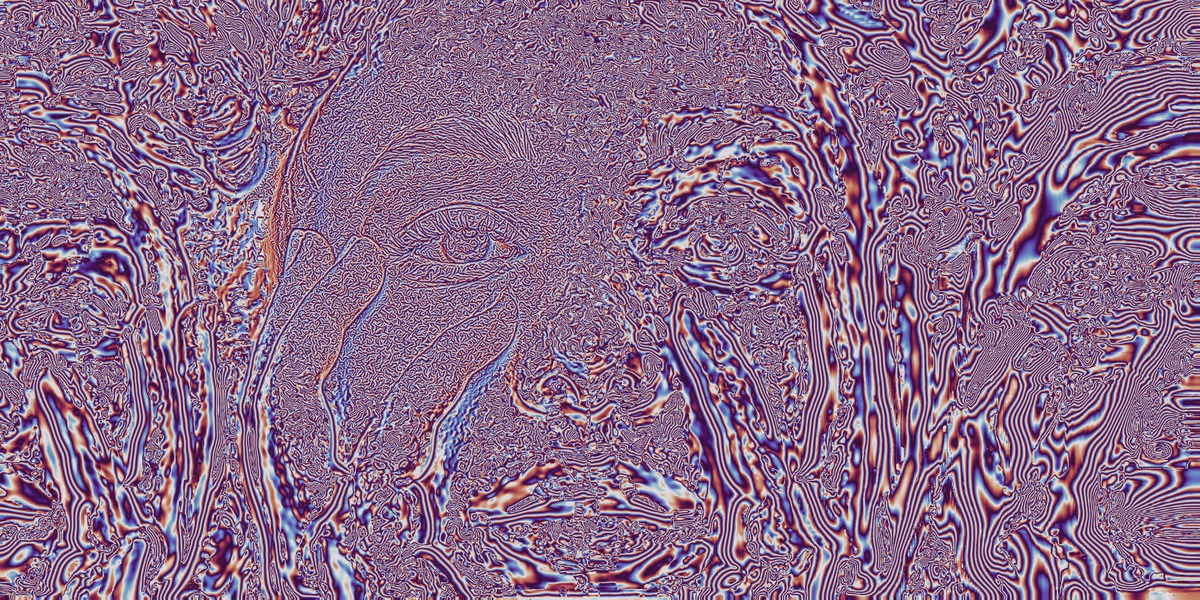


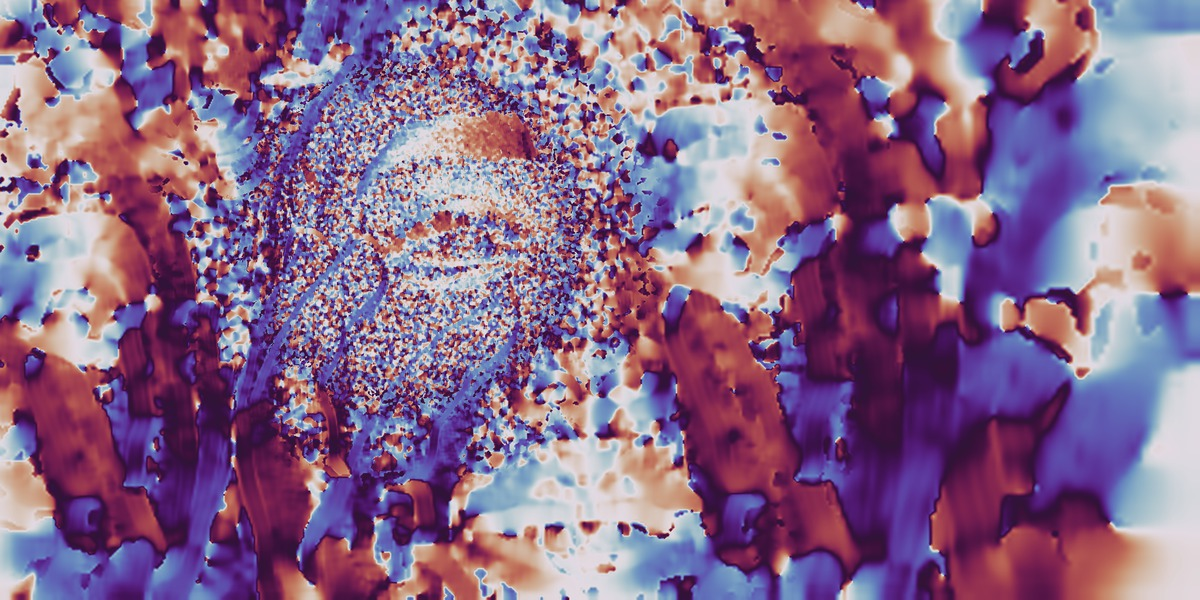


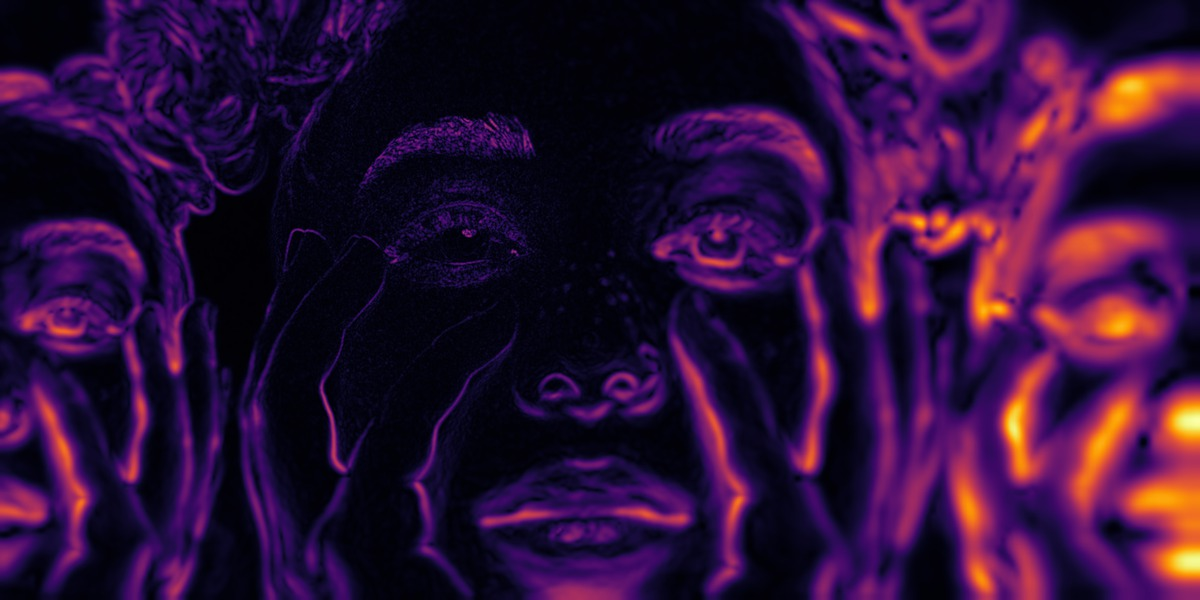


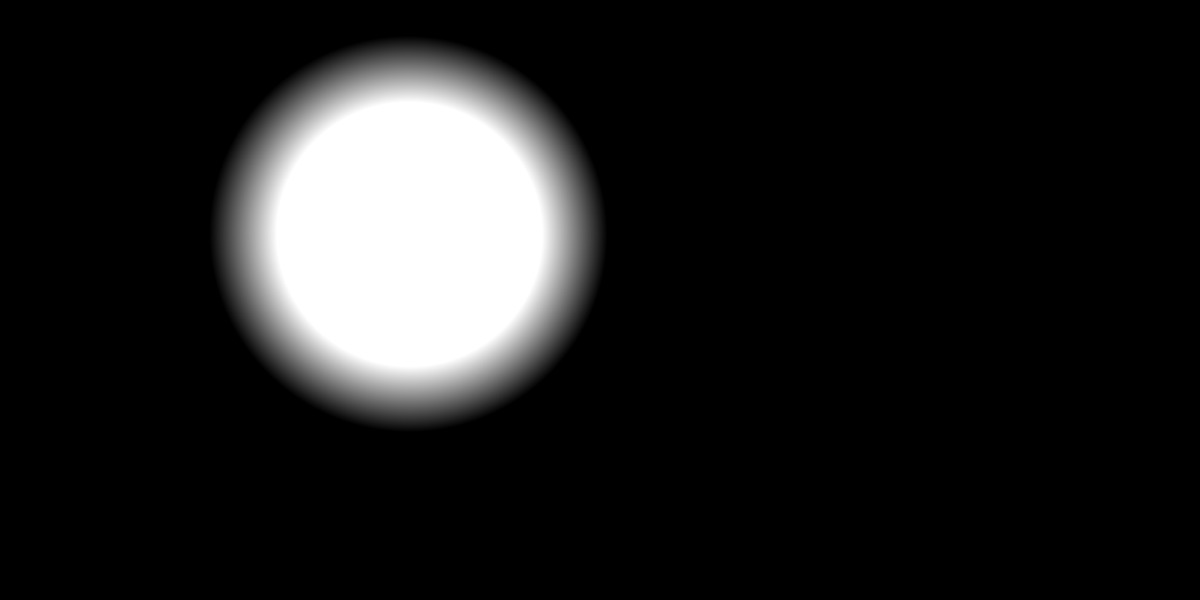

In [13]:
# render images
isu.show(maps.y[0]['phase_rep'].cpu(), title='Repaired Phase (L0)', color='twilight',
         max_width=isu.DISPLAY_WIDTH)
isu.show(maps.y[0]['dir_rep'].cpu(), title='Repaired Orientation (L0)',
         color='twilight', max_width=isu.DISPLAY_WIDTH)
isu.show(maps.y[0]['intensity_rep'].cpu(), title='Repaired Intensity (L0)',
         color='inferno', max_width=isu.DISPLAY_WIDTH)
isu.show(maps.a[0]['mask_FR'].cpu(), title='Mask (L0): 1 = kept, 0 = replaced',
         color='gray', vmin=0, vmax=1, max_width=isu.DISPLAY_WIDTH)

## Synthesis
`generate_noise` builds one noise band per level below the cutoff from the repaired statistics. `get_noise_enhancement` upsamples the bands, fades each one out inside its mask and sums them, so noise is only added where detail is missing.

In [14]:
maps.y = noise_gen.generate_noise(maps.y, maps.cutoff)
noise_enhancement = noise_gen.get_noise_enhancement(maps.a, maps.cutoff)


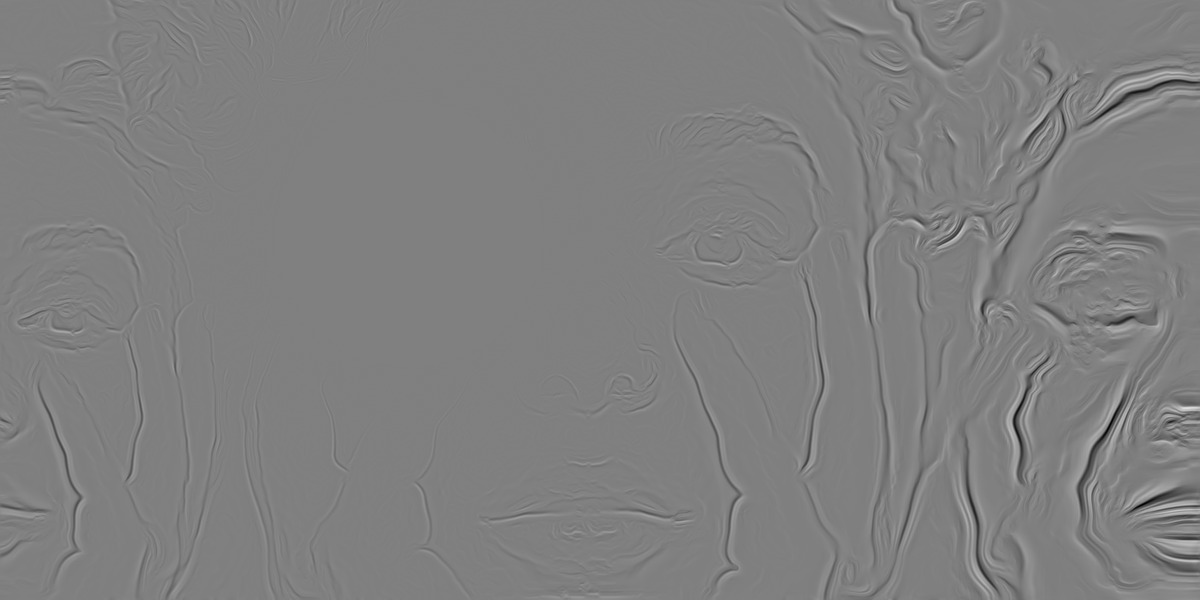


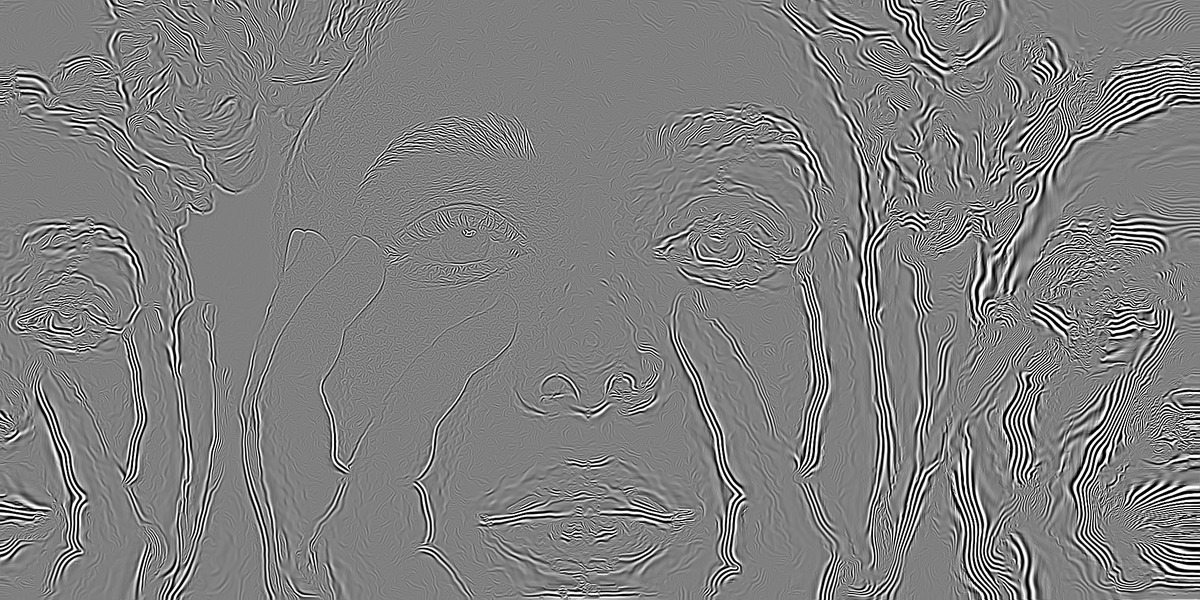
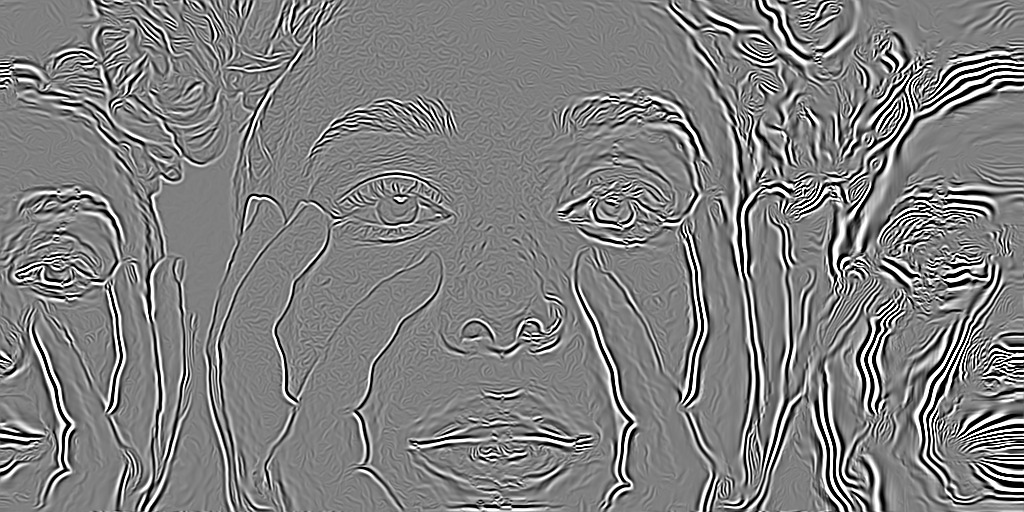
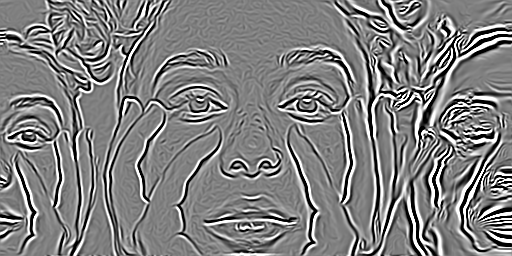
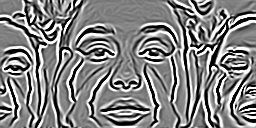

In [15]:
# render images
isu.show(noise_enhancement.cpu(), title='Noise Enhancement', color='gray',
         vsymmetric=True, max_width=isu.DISPLAY_WIDTH)
isu.show_multiple([n.cpu() for n in noise_gen.noises_small],  # one band per level
                  title=[f'Noise L{i}' for i in range(len(noise_gen.noises_small))],
                  color='gray', vmin=-0.05, vmax=0.05,
                  max_columns=2, row_width=isu.DISPLAY_WIDTH)

## Composition
`isu.compose_rgb` adds the noise to the luma of the foveated image and converts the result to RGB. The final viewer compares the original, the foveated image, the foveated image with noise, and the noise alone (around mid-gray). Drag the slider to compare; A and B can be chosen from the menus.

In [16]:
final_img_rgb = isu.compose_rgb(img.fov, noise_enhancement)  # noise added to the luma
foveated_rgb = isu.compose_rgb(img.fov)
noise_rgb = (noise_enhancement + 0.5).clamp(0, 1).repeat(1, 3, 1, 1)  # around mid-gray


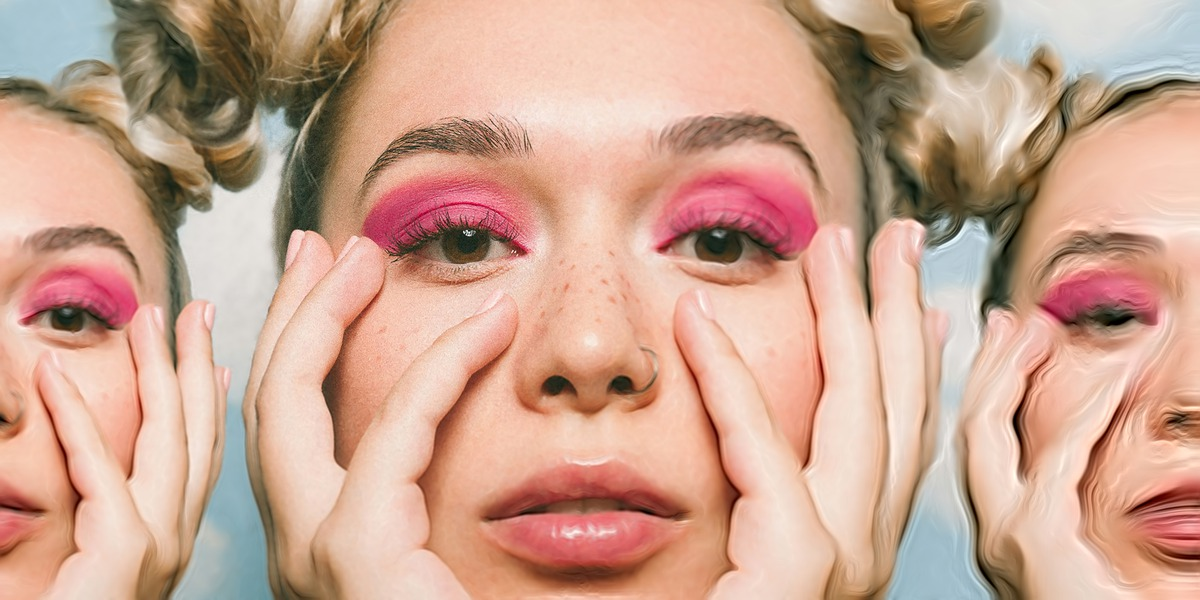
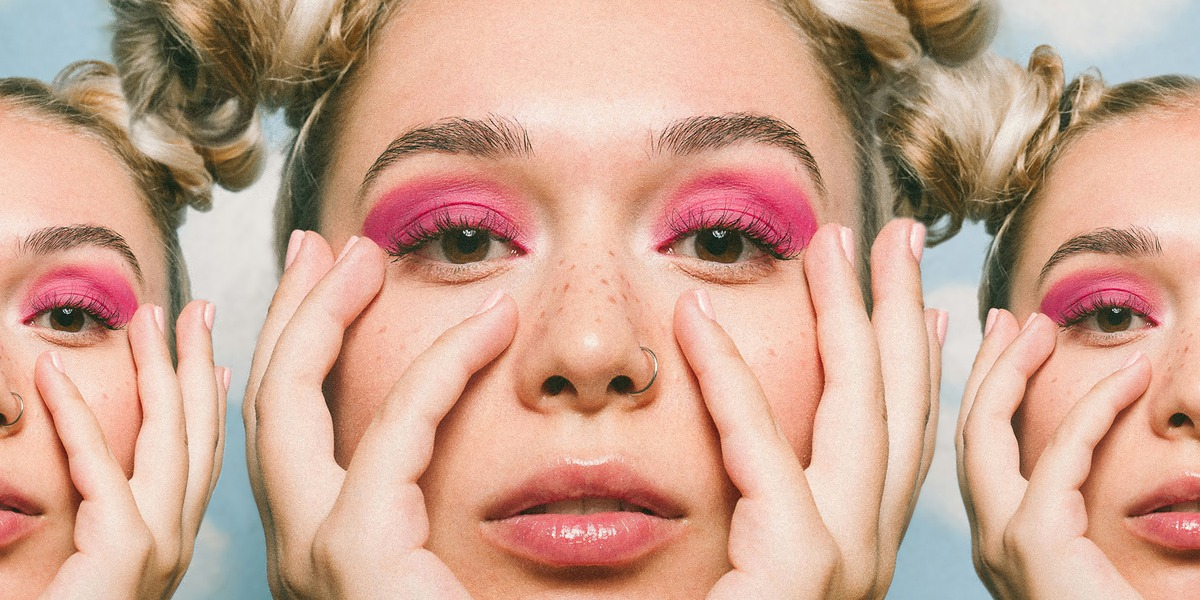
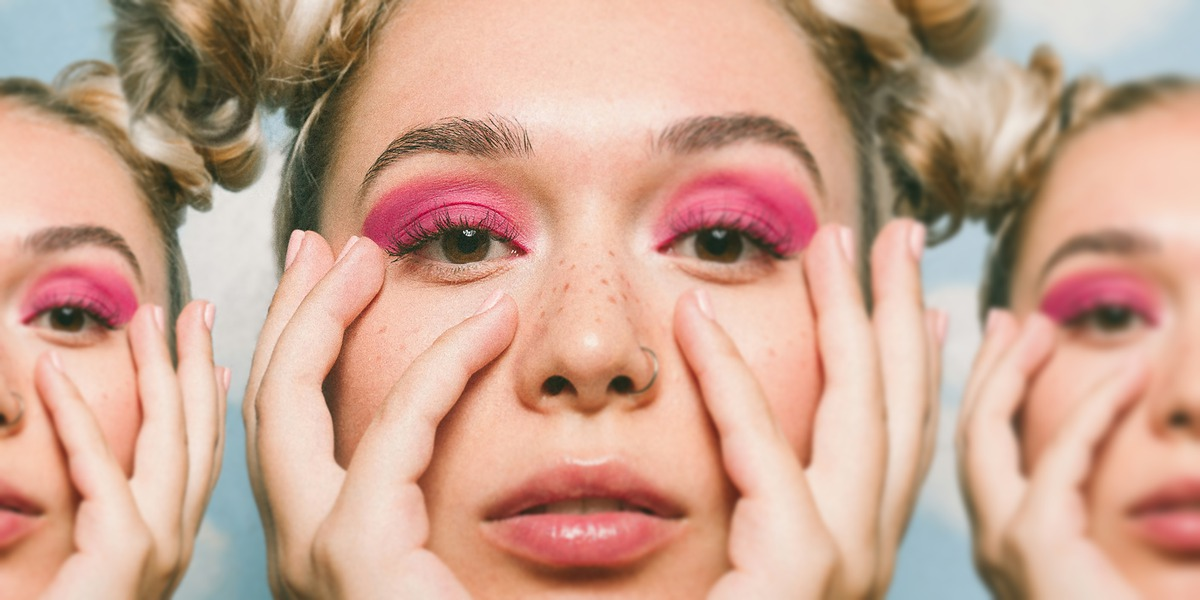
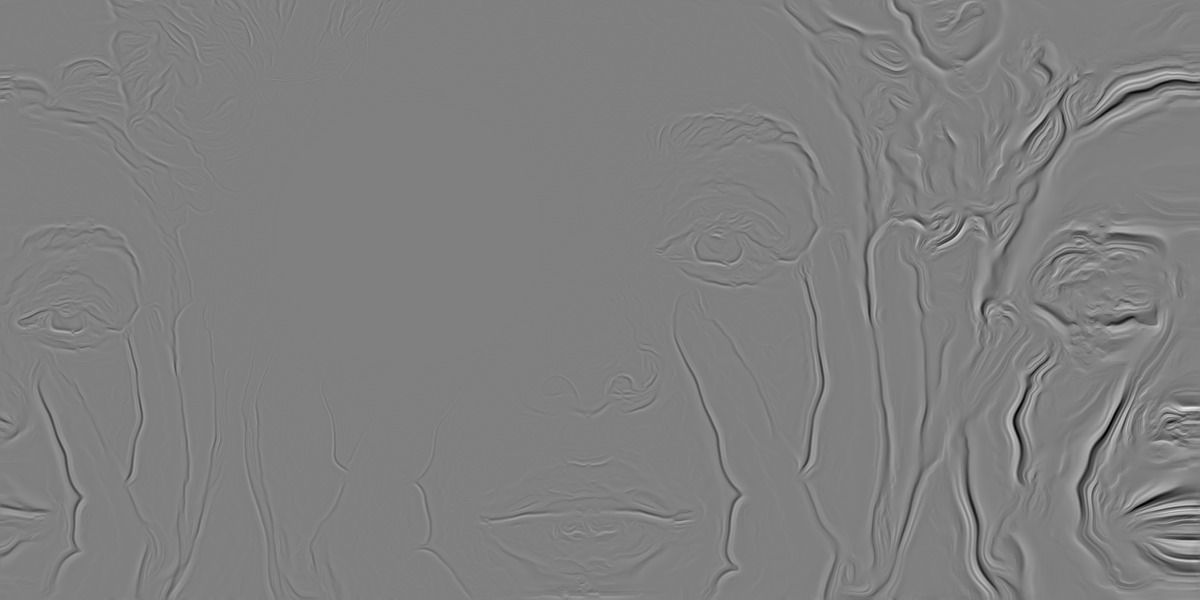
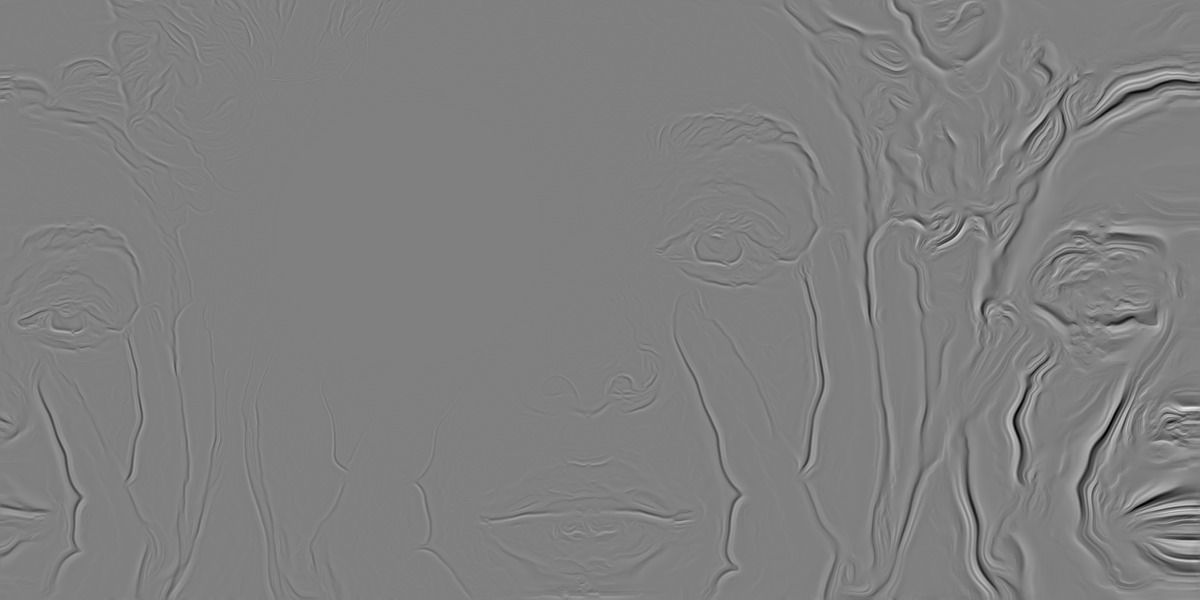
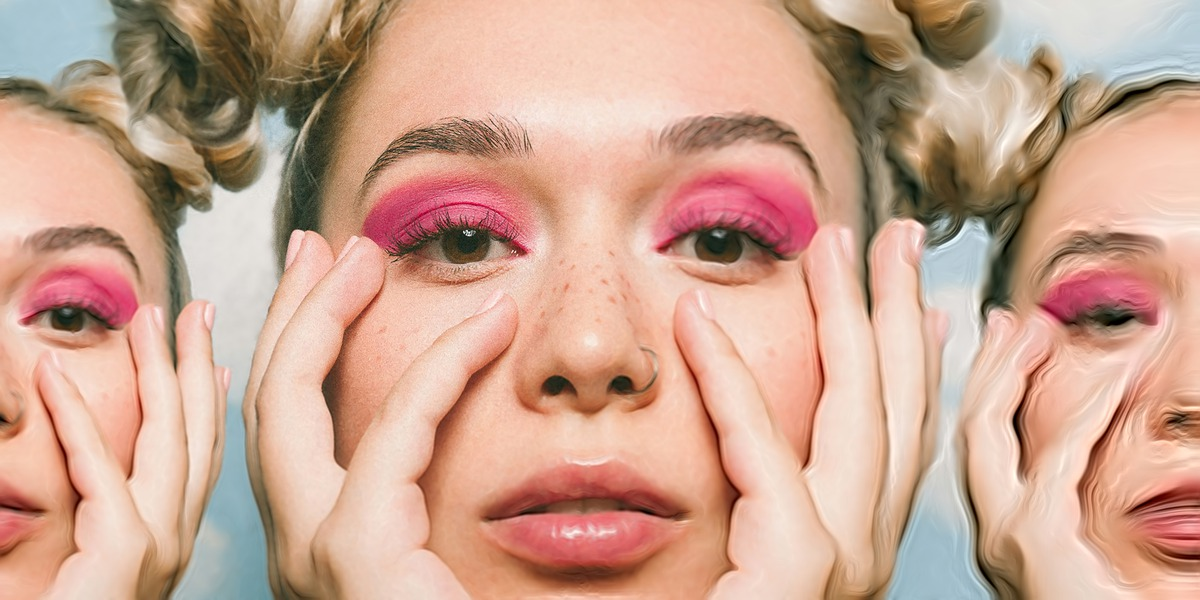

In [17]:
# render images
isu.show_compare(
    [final_img_rgb.cpu(), img.rgb.cpu(), foveated_rgb.cpu(), noise_rgb.cpu()],
    ['Foveated + Noise', 'Original', 'Foveated', 'Noise'],
    title='Final Image',
)

---
The main pipeline ends here. Everything below is optional: variations of the pipeline that reuse the objects from above.

<br><br><br><br><br>

# Part 3: Experiments
Example outputs beyond the standard pipeline. They reuse the setup from above (`DEVICE`, `view_config`, `noise_gen`, `img`):

1. **Statistic fidelity**: blend each local statistic (intensity, direction, phase) between its original value and a fixed random field.
2. **Uniform foveation**: one pyramid level for the whole image instead of the eccentricity-dependent one.
3. **Statistic maps per layer**: measured and repaired intensity, orientation and phase and the noise band of every synthesized level, analyzed on the foveated image.

Experiments 1 and 2 can be explored interactively in the viewer on our website. Here, each renders one example image; write your own loop around it to produce more.

In [18]:
IMG_PATH = img.path                    # image loaded above
CROP = (0, 512 + 64, 1024 - 64, 2048)  # region shown below (y0, y1, x0, x1)


def crop_img(t):
    y0, y1, x0, x1 = CROP
    return t[..., y0:y1, x0:x1].cpu()


def analyze(img, view_config, repair=True, foveated=False):
    """Runs the analysis (and optionally the repair); returns the Worm.

    foveated=False analyzes the full-res original (as in the main pipeline),
    foveated=True the foveated image img.fov.
    """
    ycbcr = img.fov if foveated else img.ycbcr
    maps = Worm(device=DEVICE, img=ycbcr,
                pyr_level_map=view_config.pyr_level_map,
                MAX_DEPTH=MAX_PYR_DEPTH)
    maps.y = maps.compute_R(maps.y)
    maps.y = maps.compute_theta(maps.y)
    maps.y = maps.compute_steered_G_H(maps.y)
    maps.y = maps.compute_phase(maps.y)
    maps.y = maps.compute_intensity_modulators(maps.y)
    maps.y = maps.add_repaired_layer_proxies(maps.y)  # without repair: measured values
    if repair:
        maps.y = maps.repair_intensity(maps.y)
        maps.y = maps.repair_orientation(maps.y)
        maps.y = maps.repair_phase(maps.y)
    return maps


def synthesize(img, maps, keep_intensity=1.0, keep_dir=1.0, keep_phase=1.0,
               seed=42):
    """Generates the noise and composes the final image.

    Returns (final_img_rgb, noise_enhancement).
    """
    maps.y = noise_gen.generate_noise(
        maps.y, maps.cutoff, keep_intensity=keep_intensity,
        keep_dir=keep_dir, keep_phase=keep_phase, seed=seed)
    noise_enhancement = noise_gen.get_noise_enhancement(maps.a, maps.cutoff)
    return isu.compose_rgb(img.fov, noise_enhancement), noise_enhancement


def show_layer_maps(maps, noises, L):
    """Level L: measured and repaired statistics (one row each), noise band."""
    if L >= maps.cutoff:
        print(f'Level {L} is not synthesized (cutoff: L{maps.cutoff}).')
        return
    y = maps.y[L]
    for kind, suffix in [('Measured', ''), ('Repaired', '_rep')]:
        isu.show_multiple(
            [y['intensity' + suffix].cpu(), y['dir' + suffix].cpu(),
             y['phase' + suffix].cpu()],
            title=[f'{kind} Intensity (L{L})', f'{kind} Orientation (L{L})',
                   f'{kind} Phase (L{L})'],
            color=['inferno', 'twilight', 'twilight'],
            vsymmetric=[False, True, True],  # angles: ranges around 0
            row_width=isu.DISPLAY_WIDTH)
    isu.show(noises[L].cpu(), title=f'Noise (L{L})', color='gray', vsymmetric=True,
             max_width=isu.DISPLAY_WIDTH)

## Experiment 1: Statistic Fidelity
`KEEP_INTENSITY`, `KEEP_DIR` and `KEEP_PHASE` set how much of each original statistic is used for the synthesis: **1 = original, 0 = random**. Values in between blend the original with a random field; angles (direction, phase) are blended on the unit circle.

The random fields come from `SEED`, so they are the same for every combination: changing a `KEEP_*` value interpolates between one fixed random noise and the noise built from the original statistics.

Two variants, chosen with `repair` in `analyze()`:
- **Reconstructed** (`repair=True`): statistics in the periphery are extrapolated from coarser levels, as in the real pipeline.
- **Ground Truth** (`repair=False`): the noise uses the statistics measured on the original image at every level. This is the best the repair could possibly achieve.

The analysis does not depend on the `KEEP_*` values, so one `analyze()` call can be reused for any number of `synthesize()` calls (about 2–3 s each on a CPU).

In [19]:
KEEP_INTENSITY = 1.0  # 1 = original, 0 = random
KEEP_DIR       = 0.0
KEEP_PHASE     = 0.5

SEED = 42

maps = analyze(img, view_config, repair=True)  # repair=False: Ground Truth variant
final_img_rgb, noise_enhancement = synthesize(
    img, maps, keep_intensity=KEEP_INTENSITY, keep_dir=KEEP_DIR,
    keep_phase=KEEP_PHASE, seed=SEED)


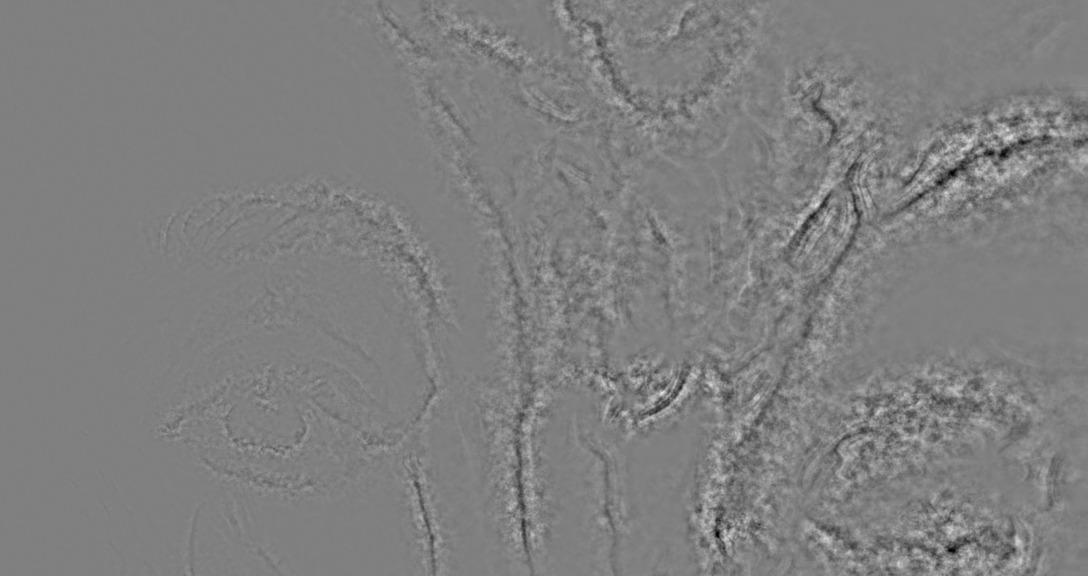
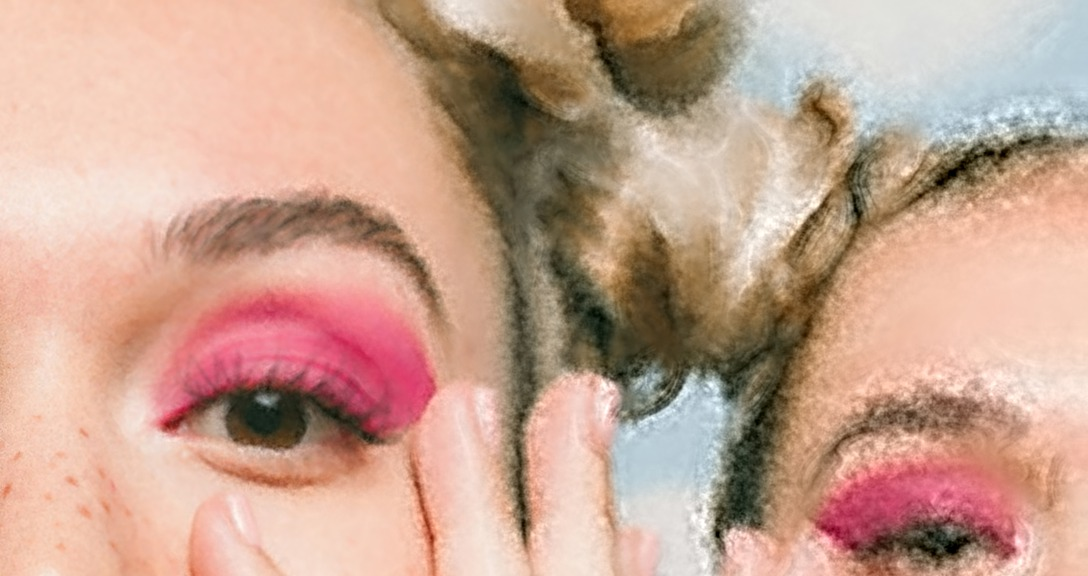

In [20]:
# render images
isu.show_multiple([crop_img(noise_enhancement + 0.5), crop_img(final_img_rgb)],
                  title=['Noise', 'Final Image'], color='gray',
                  vmin=0, vmax=1, showColorbar=False)

## Experiment 2: Uniform Foveation
`uniform_level` replaces the eccentricity-dependent pyramid level map with one constant level for the whole image.

The foveated image here is the **Gaussian pyramid level itself**, upsampled to full resolution (`Worm.compute_foveated_imgs`), i.e. the same kind of stimulus as in the calibration study. For non-integer levels, the two neighboring levels are blended. Only the upsampling differs from the study: `isu.upsample` instead of `F.interpolate(align_corners=True)`, which removes the study's half-pixel shift per level.

`LEVEL` must lie between 0 and `MAX_PYR_DEPTH - 1` (here 4), since the `Worm` only builds that many levels for the foveation; larger values raise an error. At level 0 nothing is blurred, so no noise is added.

`Image` and `Worm` read the maps from the `ViewConfig` when they are created, so they are rebuilt for every level.

**Why the noise is weaker at low levels:** the noise amplitude per level comes from a line fitted through the Laplacian standard deviations from the cutoff level on (`compute_intensity_modulators`). With a uniform level, the cutoff equals that level, so for `LEVEL = 2` the line is fitted through levels 2 and coarser only. For this image it rises with the level, and extrapolated to level 0 it becomes negative and is clamped to 0: level 0 gets no noise and level 1 only a weak one. This is the method as published, not a bug; the web version's weighted fit over all bands avoids it.

In [21]:
LEVEL = 4  # 0 to MAX_PYR_DEPTH - 1 (here 4); non-integer values blend two levels


def pyramid_foveation(maps):
    """YCbCr image from the upsampled Gaussian pyramid levels."""
    maps.compute_foveated_imgs()
    chroma = [maps.cb[0]['fov'], maps.cr[0]['fov']] if maps.cb is not None else []
    return torch.cat([maps.y[0]['fov']] + chroma, dim=1)


def uniform_foveation(level):
    """Returns (foveated_rgb, foveated_plus_noise_rgb) for one constant level."""
    view_config_u = ViewConfig(
        device=DEVICE, screen_width_cm=SCREEN_WIDTH_CM,
        screen_width_px=SCREEN_WIDTH_PX, img_size=view_config.img_size,
        viewing_distance=view_config.viewing_distance, uniform_level=level)
    img_u = Image(device=DEVICE, path=IMG_PATH, kernels=view_config_u.kernel_map)
    maps_u = analyze(img_u, view_config_u, repair=True)
    fov_u = pyramid_foveation(maps_u)
    maps_u.y = noise_gen.generate_noise(maps_u.y, maps_u.cutoff)
    noise_u = noise_gen.get_noise_enhancement(maps_u.a, maps_u.cutoff)
    return isu.compose_rgb(fov_u), isu.compose_rgb(fov_u, noise_u)


fov_rgb, fov_noise_rgb = uniform_foveation(LEVEL)


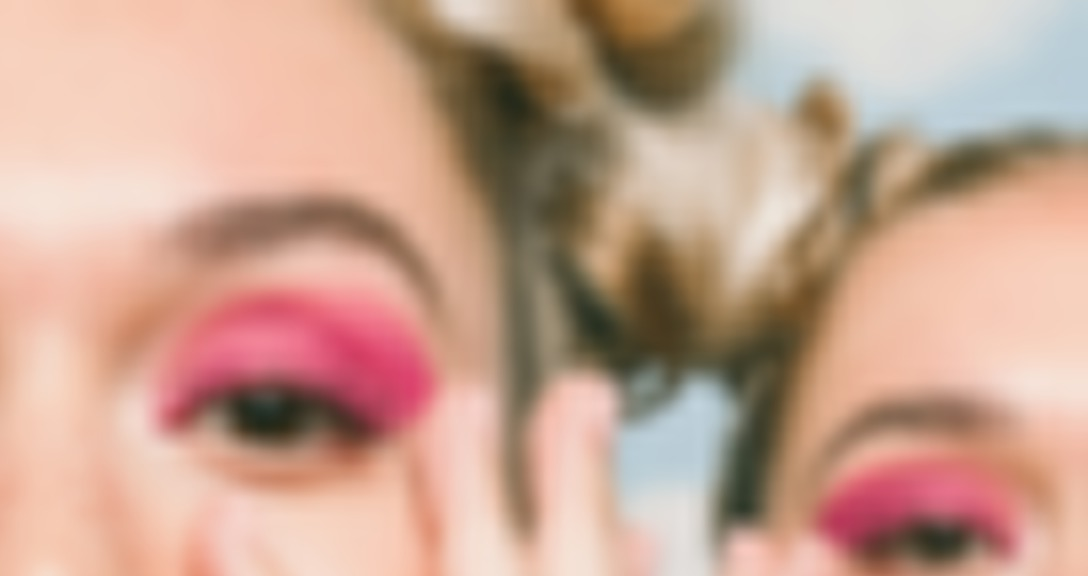
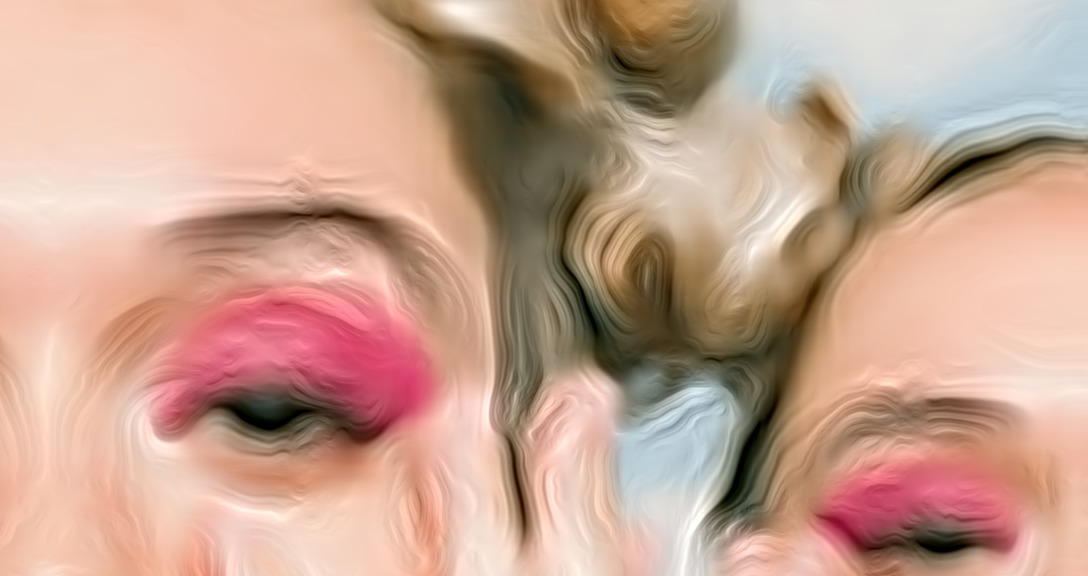

In [22]:
# render images
isu.show_multiple([crop_img(fov_rgb), crop_img(fov_noise_rgb)],
                  title=[f'Foveated (Level {LEVEL})', 'Foveated + Noise'],
                  showColorbar=False)

## Experiment 3: Statistic Maps per Layer
Shows, for every synthesized level at the level's own resolution (L0 is the finest), the measured intensity, orientation and phase in one row, the repaired ones in the next row, and the resulting noise band at full width.

Unlike the main pipeline, the statistics here are measured on the **foveated image** `img.fov`, i.e. on what the method would receive in principle (`analyze(..., foveated=True)`). The measured maps therefore show what the foveation leaves of each level: inside the level's mask the structure of the image, outside it only smooth, blurred-away values. The repaired maps show what the repair makes of them: outside the mask, the measured values are replaced by values extrapolated from the coarser levels.

Orientation and phase are shown with a cyclic colormap, so that both ends of the range (orientation: -π/2 to π/2, phase: -π to π) get the same color. The noise is shown with a symmetric range around 0.

Each level is rendered in its own cell below (L0 first); run the other cells to see the coarser levels.

In [23]:
maps_fov = analyze(img, view_config, repair=True, foveated=True)  # foveated input
_ = synthesize(img, maps_fov)
noises_fov = noise_gen.noises_small  # one band per level, at the level's size


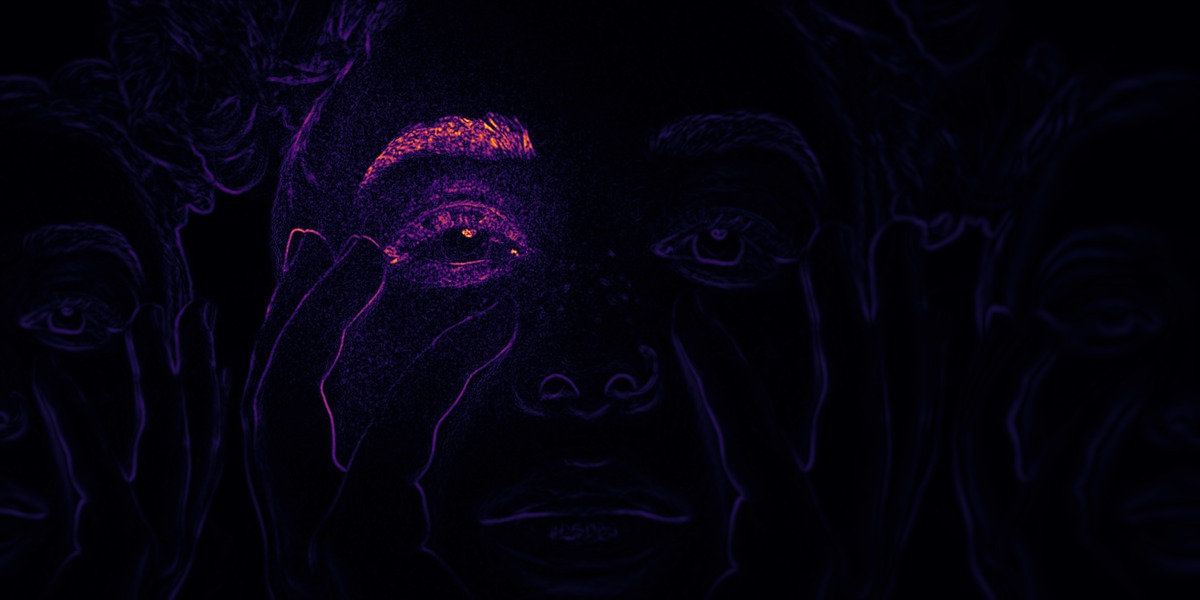
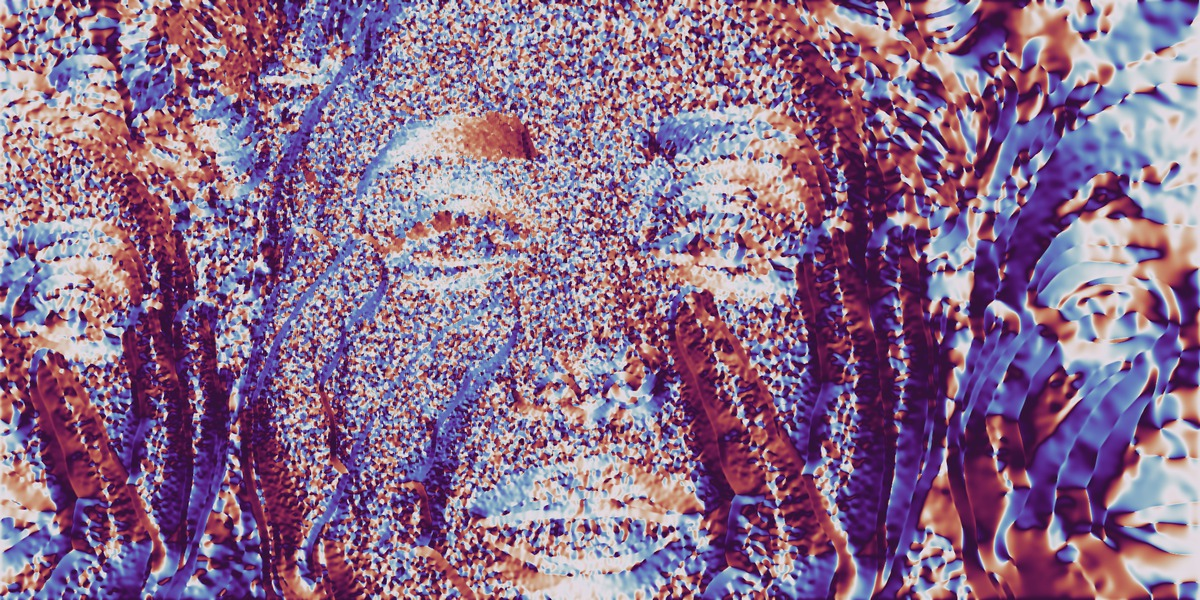
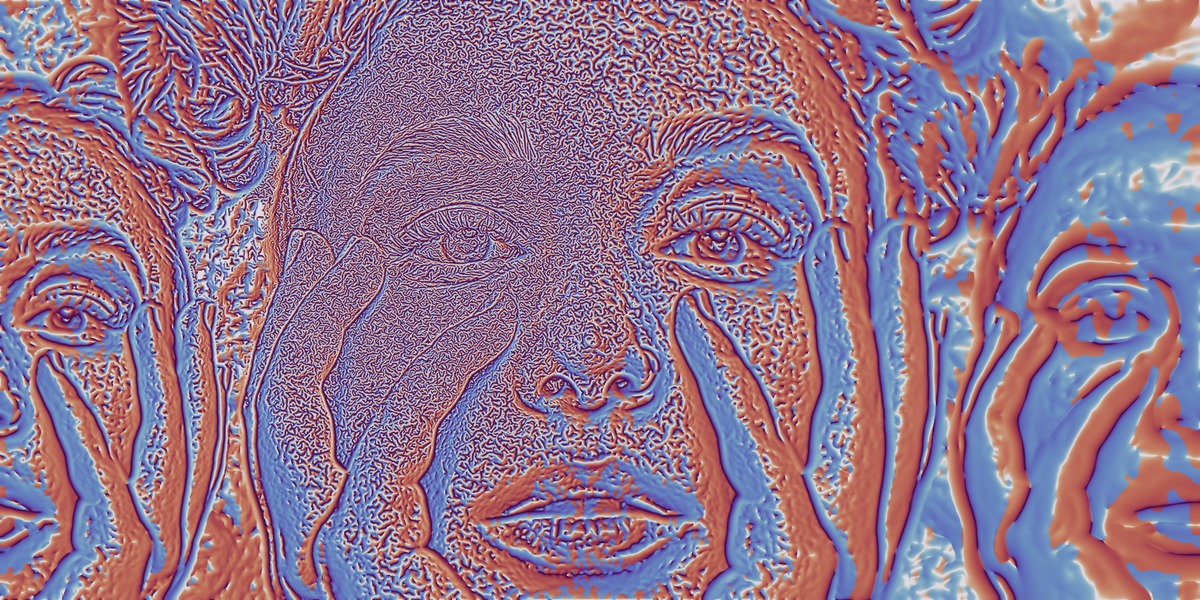


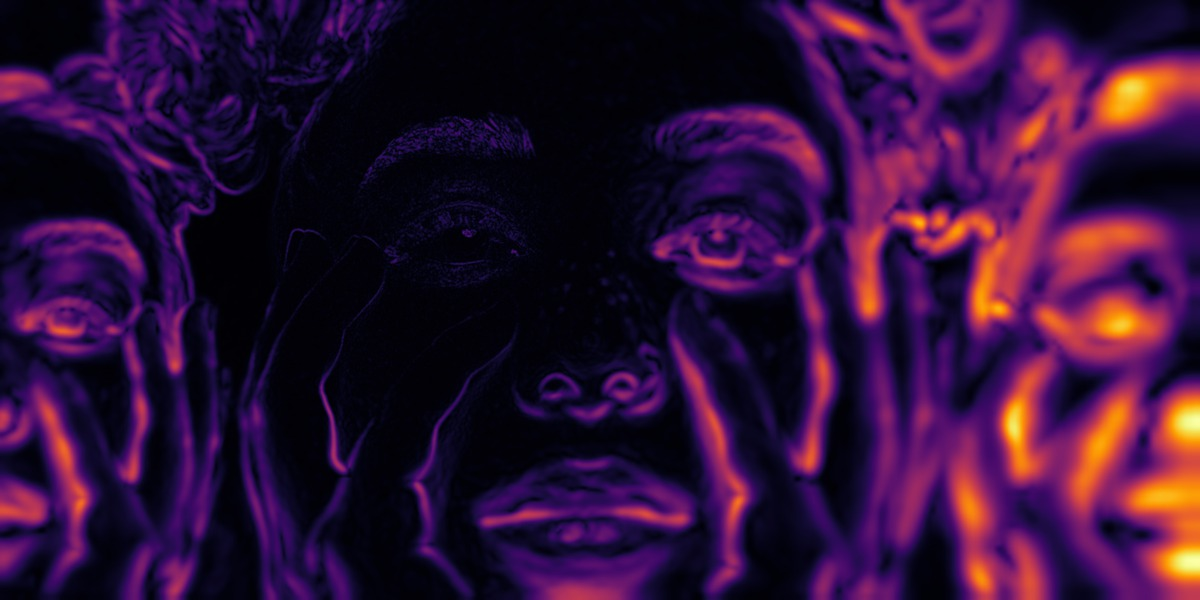
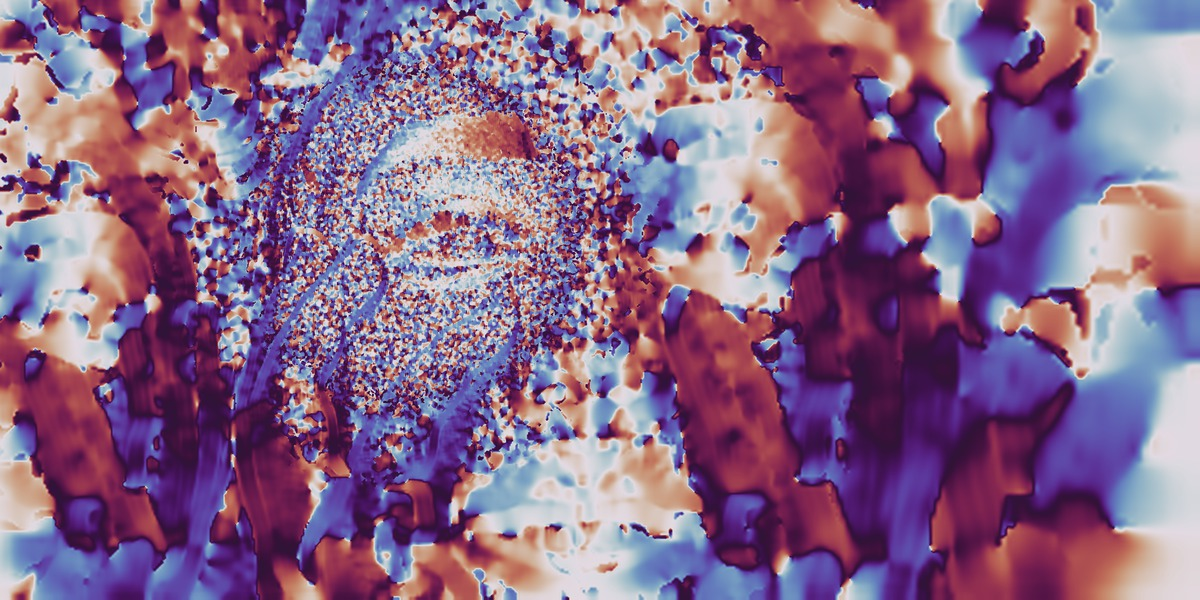
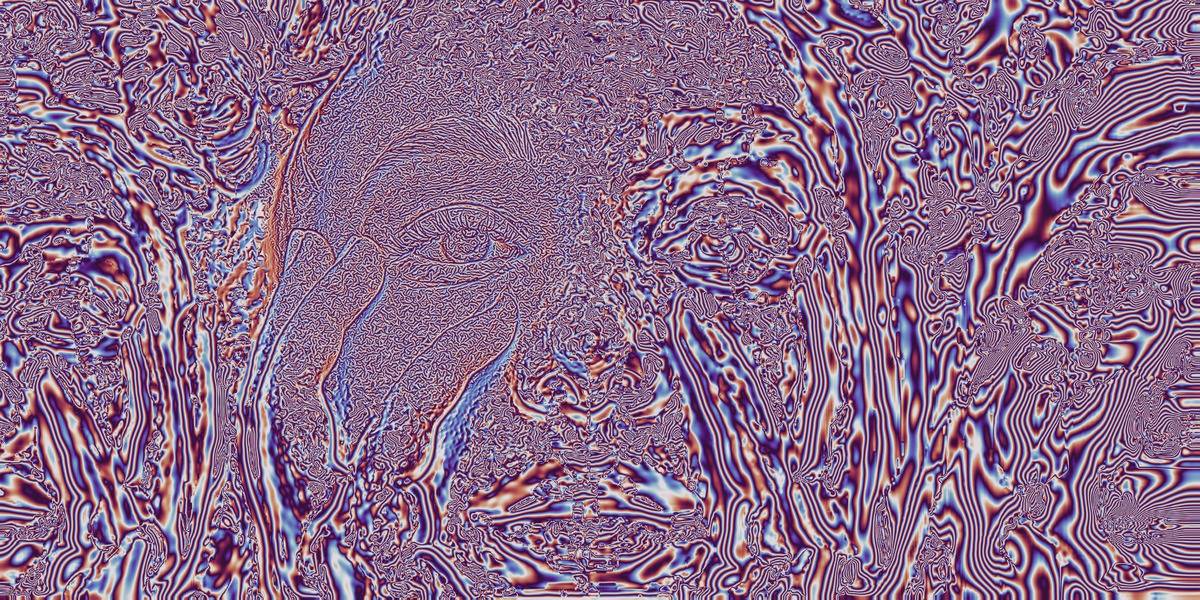


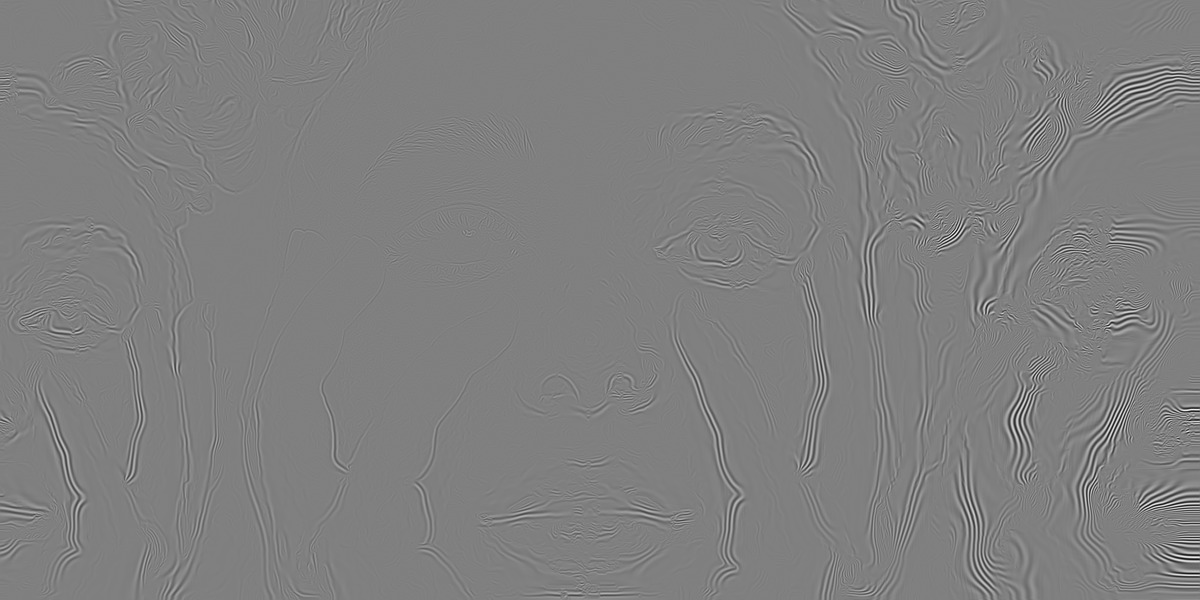

In [24]:
# render images
show_layer_maps(maps_fov, noises_fov, L=0)

In [ ]:
# render images
show_layer_maps(maps_fov, noises_fov, L=1)

In [ ]:
# render images
show_layer_maps(maps_fov, noises_fov, L=2)

In [ ]:
# render images
show_layer_maps(maps_fov, noises_fov, L=3)